# BERTurk Multi-Label Intent Training

This notebook trains `dbmdz/bert-base-turkish-cased` on `deprem-private/intent_test_v13_anonymized`
using the dataset's original multi-label intent annotations.


In [ ]:
!pip install -q transformers datasets accelerate scikit-learn pandas numpy


In [ ]:
import numpy as np
import torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    Trainer,
    TrainingArguments,
)


In [ ]:
MODEL_NAME = 'dbmdz/bert-base-turkish-cased'
DATASET_NAME = 'deprem-private/intent_test_v13_anonymized'
MAX_LENGTH = 256
TEST_SIZE = 0.15
RANDOM_SEED = 42
THRESHOLD = 0.5


In [ ]:
dataset = load_dataset(DATASET_NAME)
dataset


In [ ]:
all_labels = set()
for row in dataset['train']:
    for label in row['label']:
        all_labels.add(label)

label_list = sorted(all_labels)
label2id = {label: idx for idx, label in enumerate(label_list)}
id2label = {idx: label for label, idx in label2id.items()}

print('Label sayısı:', len(label_list))
print(label_list)


In [ ]:
def encode_example(example):
    multi_hot = [0.0] * len(label_list)
    for label in example['label']:
        multi_hot[label2id[label]] = 1.0
    example['labels'] = multi_hot
    example['text'] = example['image_url']
    return example

dataset = dataset.map(encode_example)
dataset['train'][0]


In [ ]:
split_dataset = dataset['train'].train_test_split(test_size=TEST_SIZE, seed=RANDOM_SEED)
train_ds = split_dataset['train']
val_ds = split_dataset['test']

print(train_ds)
print(val_ds)


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(
        examples['text'],
        truncation=True,
        padding='max_length',
        max_length=MAX_LENGTH,
    )

train_ds = train_ds.map(tokenize_function, batched=True)
val_ds = val_ds.map(tokenize_function, batched=True)

keep_cols = ['input_ids', 'attention_mask', 'labels']
train_ds = train_ds.remove_columns([c for c in train_ds.column_names if c not in keep_cols])
val_ds = val_ds.remove_columns([c for c in val_ds.column_names if c not in keep_cols])

train_ds.set_format('torch')
val_ds.set_format('torch')


In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_list),
    id2label=id2label,
    label2id=label2id,
    problem_type='multi_label_classification',
)


In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = 1 / (1 + np.exp(-logits))
    preds = (probs >= THRESHOLD).astype(int)

    return {
        'micro_f1': f1_score(labels, preds, average='micro', zero_division=0),
        'macro_f1': f1_score(labels, preds, average='macro', zero_division=0),
        'samples_f1': f1_score(labels, preds, average='samples', zero_division=0),
        'subset_accuracy': accuracy_score(labels, preds),
    }


In [ ]:
training_args = TrainingArguments(
    output_dir='./berturk-deprem-intent',
    eval_strategy='epoch',
    save_strategy='epoch',
    logging_strategy='steps',
    logging_steps=50,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=4,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model='micro_f1',
    greater_is_better=True,
    fp16=torch.cuda.is_available(),
    report_to='none',
)


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)


In [ ]:
trainer.train()


In [ ]:
metrics = trainer.evaluate()
metrics


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure metrics is defined
metrics = trainer.evaluate()

metric_names = ['Micro F1', 'Macro F1', 'Samples F1', 'Subset Accuracy']
metric_values = [
    metrics['eval_micro_f1'],
    metrics['eval_macro_f1'],
    metrics['eval_samples_f1'],
    metrics['eval_subset_accuracy'],
]

metrics_df = pd.DataFrame({
    'Metric': metric_names,
    'Value': metric_values,
})

plt.figure(figsize=(10, 6))
sns.barplot(x='Metric', y='Value', data=metrics_df, palette='viridis')
plt.ylim(0, 1.0)
plt.title('Model Performance Metrics')
plt.ylabel('Score')
plt.xlabel('Metric')
for index, row in metrics_df.iterrows():
    plt.text(row.name, row.Value + 0.02, round(row.Value, 4), color='black', ha="center")
plt.show()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: dbmdz/bert-base-turkish-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Samples F1,Subset Accuracy,Micro Precision,Macro Precision,Micro Recall,Macro Recall
1,0.201629,0.161839,0.673813,0.242336,0.648251,0.560656,0.823970,0.393255,0.569948,0.216291
2,0.141857,0.123001,0.799451,0.430323,0.795589,0.688525,0.850877,0.514794,0.753886,0.400068
3,0.106234,0.108763,0.813187,0.475847,0.804910,0.688525,0.865497,0.599638,0.766839,0.430382
4,0.090785,0.100701,0.844384,0.527930,0.844254,0.754098,0.883853,0.620561,0.808290,0.486073


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

{'eval_loss': 0.10070087760686874, 'eval_micro_f1': 0.8443843031123139, 'eval_macro_f1': 0.5279304440076699, 'eval_samples_f1': 0.8442544886807183, 'eval_subset_accuracy': 0.7540983606557377, 'eval_micro_precision': 0.8838526912181303, 'eval_macro_precision': 0.6205609363681498, 'eval_micro_recall': 0.8082901554404145, 'eval_macro_recall': 0.48607322068456793, 'eval_runtime': 1.2536, 'eval_samples_per_second': 243.309, 'eval_steps_per_second': 31.112, 'epoch': 4.0}


/tmp/ipykernel_7090/1342967786.py:150: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Metric', y='Value', data=metrics_df, palette='viridis')


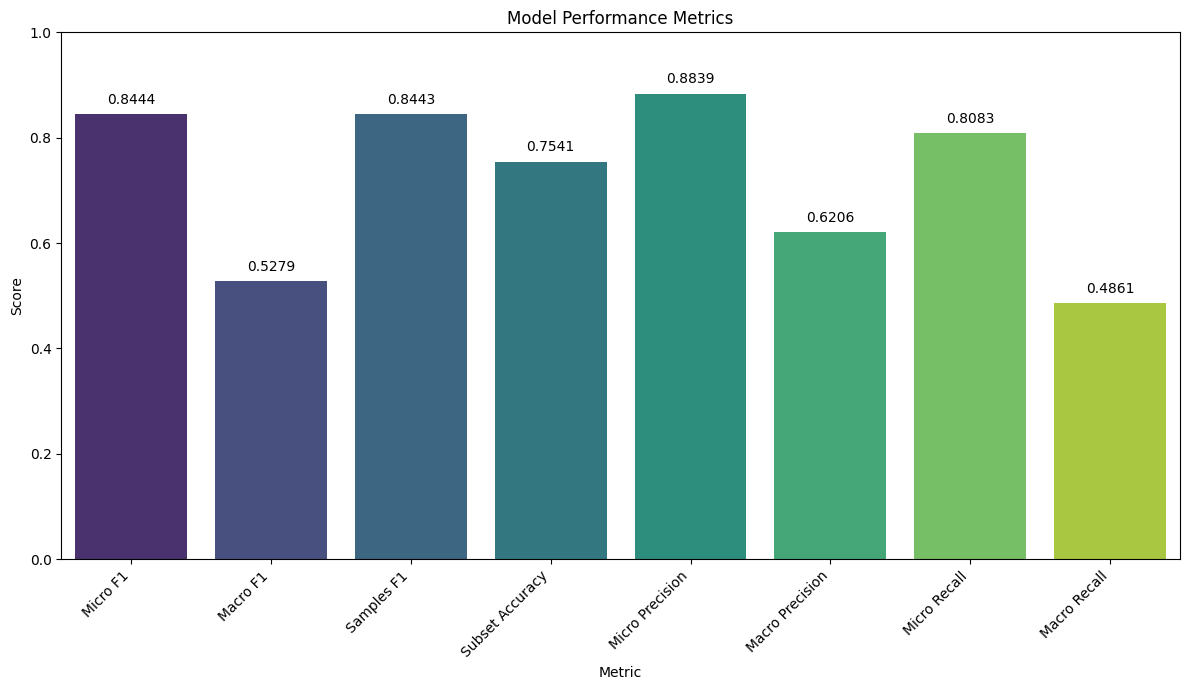

In [5]:
import numpy as np
import torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    Trainer,
    TrainingArguments,
)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- 1. Constants Definition ---
MODEL_NAME = 'dbmdz/bert-base-turkish-cased'
DATASET_NAME = 'deprem-private/intent_test_v13_anonymized'
MAX_LENGTH = 256
TEST_SIZE = 0.15
RANDOM_SEED = 42
THRESHOLD = 0.5

# --- 2. Dataset Loading and Label Encoding ---
dataset = load_dataset(DATASET_NAME)

all_labels = set()
for row in dataset['train']:
    for label in row['label']:
        all_labels.add(label)

label_list = sorted(list(all_labels))
label2id = {label: idx for idx, label in enumerate(label_list)}
id2label = {idx: label for label, idx in label2id.items()}

def encode_example(example):
    multi_hot = [0.0] * len(label_list)
    for label in example['label']:
        multi_hot[label2id[label]] = 1.0
    example['labels'] = multi_hot
    example['text'] = example['image_url'] # Assuming image_url contains the text
    return example

dataset = dataset.map(encode_example)

# --- 3. Dataset Splitting ---
split_dataset = dataset['train'].train_test_split(test_size=TEST_SIZE, seed=RANDOM_SEED)
train_ds = split_dataset['train']
val_ds = split_dataset['test']

# --- 4. Tokenization ---
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(
        examples['text'],
        truncation=True,
        padding='max_length',
        max_length=MAX_LENGTH,
    )

train_ds = train_ds.map(tokenize_function, batched=True)
val_ds = val_ds.map(tokenize_function, batched=True)

keep_cols = ['input_ids', 'attention_mask', 'labels']
train_ds = train_ds.remove_columns([c for c in train_ds.column_names if c not in keep_cols])
val_ds = val_ds.remove_columns([c for c in val_ds.column_names if c not in keep_cols])

train_ds.set_format('torch')
val_ds.set_format('torch')

# --- 5. Model Initialization ---
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_list),
    id2label=id2label,
    label2id=label2id,
    problem_type='multi_label_classification',
)

# --- 6. Metrics Function Definition ---
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = 1 / (1 + np.exp(-logits))
    preds = (probs >= THRESHOLD).astype(int)

    return {
        'micro_f1': f1_score(labels, preds, average='micro', zero_division=0),
        'macro_f1': f1_score(labels, preds, average='macro', zero_division=0),
        'samples_f1': f1_score(labels, preds, average='samples', zero_division=0),
        'subset_accuracy': accuracy_score(labels, preds),
        'micro_precision': precision_score(labels, preds, average='micro', zero_division=0),
        'macro_precision': precision_score(labels, preds, average='macro', zero_division=0),
        'micro_recall': recall_score(labels, preds, average='micro', zero_division=0),
        'macro_recall': recall_score(labels, preds, average='macro', zero_division=0),
    }

# --- 7. Training Arguments ---
training_args = TrainingArguments(
    output_dir='./berturk-deprem-intent',
    eval_strategy='epoch',
    save_strategy='epoch',
    logging_strategy='steps',
    logging_steps=50,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=4,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model='micro_f1',
    greater_is_better=True,
    fp16=torch.cuda.is_available(),
    report_to='none',
)

# --- 8. Trainer Initialization and Training ---
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
)

trainer.train()

# --- 9. Model Evaluation ---
metrics = trainer.evaluate()
print(metrics)

# --- 10. Plotting Metrics ---
metric_names = ['Micro F1', 'Macro F1', 'Samples F1', 'Subset Accuracy', 'Micro Precision', 'Macro Precision', 'Micro Recall', 'Macro Recall']
metric_values = [
    metrics['eval_micro_f1'],
    metrics['eval_macro_f1'],
    metrics['eval_samples_f1'],
    metrics['eval_subset_accuracy'],
    metrics['eval_micro_precision'],
    metrics['eval_macro_precision'],
    metrics['eval_micro_recall'],
    metrics['eval_macro_recall'],
]

metrics_df = pd.DataFrame({
    'Metric': metric_names,
    'Value': metric_values,
})

plt.figure(figsize=(12, 7)) # Adjusted figure size for more metrics
sns.barplot(x='Metric', y='Value', data=metrics_df, palette='viridis')
plt.ylim(0, 1.0)
plt.title('Model Performance Metrics')
plt.ylabel('Score')
plt.xlabel('Metric')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better readability
for index, row in metrics_df.iterrows():
    plt.text(row.name, row.Value + 0.02, round(row.Value, 4), color='black', ha="center")
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

In [ ]:
trainer.save_model('./berturk-deprem-intent-final')
tokenizer.save_pretrained('./berturk-deprem-intent-final')


In [7]:
from ipywidgets import Textarea
from IPython.display import display

def predict_intent(text_input):
    inputs = tokenizer(text_input, return_tensors='pt', truncation=True, padding=True, max_length=MAX_LENGTH)
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    model.eval()
    with torch.no_grad():
        logits = model(**inputs).logits
        probs = torch.sigmoid(logits).cpu().numpy()[0]

    predicted_labels = [label_list[i] for i, p in enumerate(probs) if p >= THRESHOLD]
    print('Tahmin edilen labellar:', predicted_labels)
    print('Skorlar:')
    for i, p in enumerate(probs):
        if p >= 0.2:
            print(label_list[i], round(float(p), 4))

# Create a text area widget for user input
text_input_widget = Textarea(
    value='Acil çadır ve battaniye ihtiyacı var. Hatay Antakya Odabaşı Mahallesi',
    description='Input Text:',
    placeholder='Enter text here',
    layout={'width': '80%', 'height': '100px'}
)

# Display the widget and call the prediction function when the value changes
print("Enter text below to get model predictions:")
display(text_input_widget)

# Run prediction with initial or changed text
predict_intent(text_input_widget.value)

Enter text below to get model predictions:


Textarea(value='Acil çadır ve battaniye ihtiyacı var. Hatay Antakya Odabaşı Mahallesi', description='Input Tex…

Tahmin edilen labellar: ['Barınma']
Skorlar:
Barınma 0.9734
Giysi 0.2363
Isinma 0.456
Yemek 0.2154
